# NephroPatch — GFR-Band Classification without HbA1c

This notebook is a cleaned version of the original staging experiment.

The original notebook reported approximately **38% accuracy**. That result came from a workflow where scaling and SMOTE occurred before the train/test split. This revision prevents train/test leakage, so the result obtained after rerunning this notebook should be treated as the reproducible holdout result.

### Important terminology
The original code derives the target directly from `GFR` using custom numeric ranges. Therefore this notebook calls the targets **GFR bands** rather than claiming that the model independently establishes a clinical CKD stage.

The original dataset produced four observed target categories in the saved notebook output. This notebook dynamically encodes whatever categories are actually present instead of hard-coding four labels.

## Imports

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBClassifier

RANDOM_STATE = 42

## Load data

In [2]:
DATA_PATH = Path("../data/Chronic_Kidney_Disease_data.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "See ../data/README.md for the expected dataset source and filename."
    )

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (1659, 54)


,PatientID,Age,Gender,Ethnicity,SocioeconomicStatus,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,...,Itching,QualityOfLifeScore,HeavyMetalsExposure,OccupationalExposureChemicals,WaterQuality,MedicalCheckupsFrequency,MedicationAdherence,HealthLiteracy,Diagnosis,DoctorInCharge
0,1,71,0,0,0,2,31.069414,1,5.128112,1.676220,...,7.556302,76.076800,0,0,1,1.018824,4.966808,9.871449,1,Confidential
1,2,34,0,0,1,3,29.692119,1,18.609552,8.377574,...,6.836766,40.128498,0,0,0,3.923538,8.189275,7.161765,1,Confidential
2,3,80,1,1,0,1,37.394822,1,11.882429,9.607401,...,2.144722,92.872842,0,1,1,1.429906,7.624028,7.354632,1,Confidential
3,4,40,0,2,0,1,31.329680,0,16.020165,0.408871,...,7.077188,90.080321,0,0,0,3.226416,3.282688,6.629587,1,Confidential
4,5,43,0,1,1,2,23.726311,0,7.944146,0.780319,...,3.553118,5.258372,0,0,1,0.285466,3.849498,1.437385,1,Confidential


## Reproduce the original GFR-band target

In [3]:
def categorize_gfr(gfr_value):
    # Preserves the ranges used in the original NephroPatch notebook.
    if 90 <= gfr_value <= 120:
        return 1
    elif 60 <= gfr_value < 90:
        return 2
    elif 30 <= gfr_value < 60:
        return 3
    elif 15 <= gfr_value < 30:
        return 4
    elif 0 <= gfr_value < 15:
        return 5
    else:
        return 6

df = df.copy()
df["GFR_Category"] = df["GFR"].apply(categorize_gfr)

print("Observed GFR categories:")
print(df["GFR_Category"].value_counts().sort_index())

Observed GFR categories:
GFR_Category
1    454
2    480
3    480
4    245
Name: count, dtype: int64


## Prepare features

In [4]:
DROP_COLUMNS = [
    "PatientID",
    "DoctorInCharge",
    "EducationLevel",
    "GFR",
    "SerumCreatinine",
    "Diagnosis",
    "ProteinInUrine",
    "ACR",
    "SerumElectrolytesSodium",
    "HbA1c",
    "SerumElectrolytesPotassium",
    "SerumElectrolytesCalcium",
    "SerumElectrolytesPhosphorus",
    "HemoglobinLevels",
    "CholesterolTotal",
    "CholesterolLDL",
    "CholesterolHDL",
    "CholesterolTriglycerides",
    "MedicalCheckupsFrequency",
    "MedicationAdherence",
    "HealthLiteracy",
]

missing_drop_columns = sorted(set(DROP_COLUMNS) - set(df.columns))
if missing_drop_columns:
    raise ValueError(f"Expected columns missing from dataset: {missing_drop_columns}")

model_df = df.drop(columns=DROP_COLUMNS).copy()

X = model_df.drop(columns="GFR_Category")
y_original = model_df["GFR_Category"]

observed_classes = sorted(y_original.unique())
class_to_index = {label: index for index, label in enumerate(observed_classes)}
index_to_class = {index: label for label, index in class_to_index.items()}
y = y_original.map(class_to_index)

print("Feature count:", X.shape[1])
print("Observed classes:", observed_classes)
print("Encoding:", class_to_index)

Feature count: 33
Observed classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Encoding: {np.int64(1): 0, np.int64(2): 1, np.int64(3): 2, np.int64(4): 3}


## Split before preprocessing

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (1327, 33)
Test shape: (332, 33)


## Train leakage-safe XGBoost pipeline

In [6]:
pipeline = Pipeline(
    steps=[
        ("scaler", MinMaxScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        (
            "model",
            XGBClassifier(
                random_state=RANDOM_STATE,
                eval_metric="mlogloss",
            ),
        ),
    ]
)

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

## Evaluate on untouched test data

Clean holdout accuracy: 25.90%

              precision    recall  f1-score   support

  GFR band 1     0.2444    0.2418    0.2431        91
  GFR band 2     0.2632    0.2604    0.2618        96
  GFR band 3     0.3113    0.3438    0.3267        96
  GFR band 4     0.1463    0.1224    0.1333        49

    accuracy                         0.2590       332
   macro avg     0.2413    0.2421    0.2412       332
weighted avg     0.2547    0.2590    0.2565       332



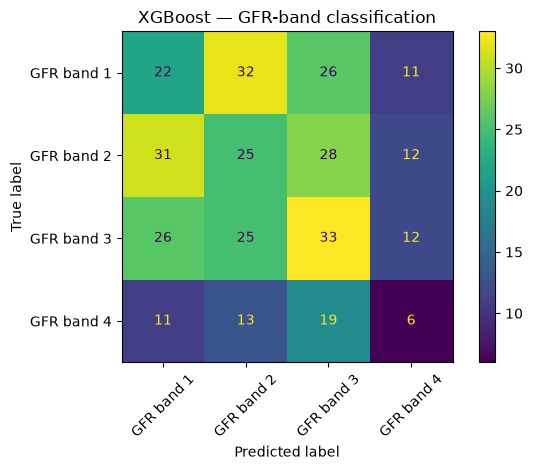

In [7]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Clean holdout accuracy: {accuracy:.2%}\n")

display_labels = [
    f"GFR band {index_to_class[i]}"
    for i in sorted(index_to_class)
]

print(
    classification_report(
        y_test,
        y_pred,
        target_names=display_labels,
        digits=4,
        zero_division=0,
    )
)

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels,
).plot(xticks_rotation=45)

plt.title("XGBoost — GFR-band classification")
plt.tight_layout()
plt.show()

## Save the complete preprocessing + model pipeline locally

In [8]:
MODEL_PATH = Path("../models/ckd_gfr_bands_without_hba1c.joblib")
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "pipeline": pipeline,
        "feature_names": X.columns.tolist(),
        "class_to_index": class_to_index,
        "index_to_class": index_to_class,
    },
    MODEL_PATH,
)

print(f"Saved locally to: {MODEL_PATH}")
print("Generated .joblib files are ignored by Git.")

Saved locally to: ../models/ckd_gfr_bands_without_hba1c.joblib
Generated .joblib files are ignored by Git.
